# 04a · Encoding ablations (one factor at a time)

Base model: ZZ map, reps = 2, linear entanglement, all three features in the order (Pu, ex, ey).
Each arm changes one thing. **Every arm re-tunes its own $(c, C)$ on the inner folds** (lecture 7, check 4), so no arm is
handicapped by settings chosen for another.

| factor | arms |
|---|---|
| feature map | angle (product), Z only (no entanglers), ZZ, Z + ZZ + ZZZ |
| repetitions | ZZ reps 1, 2, 3 |
| entanglement pattern | ZZ linear vs full, at reps 1 and 2 |
| feature-to-qubit order | which feature pairs get a ZZ term (linear map) |
| input features | drop one feature at a time (2 qubits), angle and ZZ, with the RBF SVM on the same two features |

Training size 160 (and 40 for the small-data end), seeds 0 to 4, random sampling.

In [1]:
# Make the project helper package (qsvm_rc) importable from any sub-folder
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "qsvm_rc").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: /kaggle/working/Project


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qsvm_rc import config, data_utils, metrics, models, quantum_kernels

SECTION = config.MAIN_SECTION
RESULTS_DIR = config.section_results_dir(SECTION, "ablations")
ABLATION_SIZES = [40, 160]

In [3]:
frame = data_utils.load_section(SECTION)
splits = data_utils.load_splits(SECTION)
scaler = data_utils.domain_scaler(SECTION, frame)
test_rows, band_mask = data_utils.test_indices(splits)
x_test, y_test = data_utils.features_and_labels(frame, test_rows, scaler)
test_cache = models.ExactStateCache(x_test)

## 1. Arms

In [4]:
base = {"kind": "zz", "reps": 2, "entanglement": "linear"}

arms = {
    # Feature map
    "map: angle": {"kind": "angle"},
    "map: Z only (no entanglers)": {"kind": "z", "reps": 2},
    "map: ZZ (base)": base,
    "map: Z+ZZ+ZZZ": {"kind": "pauli_zzz", "reps": 2, "entanglement": "full"},
    # Repetitions
    "reps: ZZ 1": {"kind": "zz", "reps": 1, "entanglement": "linear"},
    "reps: ZZ 3": {"kind": "zz", "reps": 3, "entanglement": "linear"},
    # Entanglement pattern
    "ent: ZZ r1 full": {"kind": "zz", "reps": 1, "entanglement": "full"},
    "ent: ZZ r2 full": {"kind": "zz", "reps": 2, "entanglement": "full"},
    # Feature-to-qubit order: linear ZZ couples qubits (0,1) and (1,2)
    "order: (ex, Pu, ey)": {**base, "features": [1, 0, 2]},
    "order: (Pu, ey, ex)": {**base, "features": [0, 2, 1]},
    # Input features (2 qubits)
    "inputs: ZZ (Pu, ex)": {**base, "features": [0, 1]},
    "inputs: ZZ (Pu, ey)": {**base, "features": [0, 2]},
    "inputs: ZZ (ex, ey)": {**base, "features": [1, 2]},
    "inputs: angle (Pu, ex)": {"kind": "angle", "features": [0, 1]},
    "inputs: angle (Pu, ey)": {"kind": "angle", "features": [0, 2]},
    "inputs: angle (ex, ey)": {"kind": "angle", "features": [1, 2]},
}


def rbf_on_features(features):
    """Tuned RBF SVM restricted to some input columns."""
    base_function = models.classical_fit_predict("rbf_svm")

    def fit_predict(x_train, y_train, x_test, seed):
        return base_function(x_train[:, features], y_train, x_test[:, features], seed)
    return fit_predict


ablation_models = {name: models.qsvm_fit_predict(spec, test_cache) for name, spec in arms.items()}
ablation_models["reference: RBF SVM"] = models.classical_fit_predict("rbf_svm")
ablation_models["inputs: RBF (Pu, ex)"] = rbf_on_features([0, 1])
ablation_models["inputs: RBF (Pu, ey)"] = rbf_on_features([0, 2])
ablation_models["inputs: RBF (ex, ey)"] = rbf_on_features([1, 2])
print(len(ablation_models), "arms")

20 arms


In [5]:
# Circuit cost of every quantum arm (overlap circuit in the rz, sx, x, cx basis)
resource_rows = []
for name, spec in arms.items():
    number_of_qubits = len(spec.get("features", [0, 1, 2]))
    overlap = quantum_kernels.overlap_template(quantum_kernels.build_feature_map(spec, number_of_qubits))
    resource_rows.append({"arm": name, **quantum_kernels.circuit_resources(quantum_kernels.transpile_for_simulation(overlap))})
resources = pd.DataFrame(resource_rows).set_index("arm")
resources

,qubits_used,depth,two_qubit_gates,total_gates
arm,,,,
map: angle,3,7,0,18
map: Z only (no entanglers),3,17,0,48
map: ZZ (base),3,39,14,70
map: Z+ZZ+ZZZ,3,69,36,100
reps: ZZ 1,3,19,6,34
reps: ZZ 3,3,59,22,106
ent: ZZ r1 full,3,25,10,40
ent: ZZ r2 full,3,51,22,82
"order: (ex, Pu, ey)",3,39,14,70


## 2. Run

In [6]:
encoding_results = models.run_learning_curve(ablation_models, frame, splits, scaler, sizes = ABLATION_SIZES,
                                             strategy = "random", save_path = RESULTS_DIR / "encoding_ablations.csv",
                                             verbose = False)
print("Saved", len(encoding_results), "rows")

Saved 200 rows


## 3. Ablation table

In [7]:
table = metrics.mean_ci_table(encoding_results, ["band_error", "test_balanced_accuracy", "test_false_safe_rate"])
diagnostic_columns = ["bandwidth", "C", "mean_offdiag", "min_eigenvalue", "target_alignment"]
diagnostics = encoding_results.groupby(["model", "train_size"])[[column for column in diagnostic_columns if column in encoding_results]].mean().round(3)
ablation_table = table.join(diagnostics)
ablation_table.to_csv(RESULTS_DIR / "encoding_ablations_summary.csv")
ablation_table

band_error  \
model                       train_size                    
ent: ZZ r1 full             40          0.435 +/- 0.028   
                            160         0.337 +/- 0.061   
ent: ZZ r2 full             40          0.459 +/- 0.023   
                            160         0.370 +/- 0.066   
inputs: RBF (Pu, ex)        40          0.465 +/- 0.009   
                            160         0.449 +/- 0.022   
inputs: RBF (Pu, ey)        40          0.489 +/- 0.011   
                            160         0.492 +/- 0.015   
inputs: RBF (ex, ey)        40          0.491 +/- 0.014   
                            160         0.487 +/- 0.011   
inputs: ZZ (Pu, ex)         40          0.466 +/- 0.009   
                            160         0.454 +/- 0.018   
inputs: ZZ (Pu, ey)         40          0.484 +/- 0.021   
                            160         0.503 +/- 0.009   
inputs: ZZ (ex, ey)         40          0.488 +/- 0.008   
                            160         0.489 +/- 0.015   
inputs: angle (Pu, ex)      40          0.468 +/- 0.008   
                            160         0.453 +/- 0.016   
inputs: angle (Pu, ey)      40          0.489 +/- 0.015   
                            160         0.493 +/- 0.015   
inputs: angle (ex, ey)      40          0.489 +/- 0.011   
                            160         0.483 +/- 0.004   
map: Z only (no entanglers) 40          0.450 +/- 0.046   
                            160         0.375 +/- 0.031   
map: Z+ZZ+ZZZ               40          0.435 +/- 0.033   
                            160         0.351 +/- 0.056   
map: ZZ (base)              40          0.453 +/- 0.003   
                            160         0.364 +/- 0.066   
map: angle                  40          0.436 +/- 0.037   
                            160         0.395 +/- 0.033   
order: (Pu, ey, ex)         40          0.475 +/- 0.032   
                            160         0.368 +/- 0.028   
order: (ex, Pu, ey)         40          0.428 +/- 0.032   
                            160         0.425 +/- 0.030   
reference: RBF SVM          40          0.443 +/- 0.023   
                            160         0.353 +/- 0.065   
reps: ZZ 1                  40          0.457 +/- 0.014   
                            160         0.363 +/- 0.061   
reps: ZZ 3                  40          0.455 +/- 0.010   
                            160         0.359 +/- 0.054   

                                       test_balanced_accuracy  \
model                       train_size                          
ent: ZZ r1 full             40                0.951 +/- 0.015   
                            160               0.982 +/- 0.009   
ent: ZZ r2 full             40                0.930 +/- 0.029   
                            160               0.975 +/- 0.014   
inputs: RBF (Pu, ex)        40                0.920 +/- 0.013   
                            160               0.919 +/- 0.012   
inputs: RBF (Pu, ey)        40                0.910 +/- 0.020   
                            160               0.912 +/- 0.042   
inputs: RBF (ex, ey)        40                0.535 +/- 0.047   
                            160               0.536 +/- 0.027   
inputs: ZZ (Pu, ex)         40                0.910 +/- 0.034   
                            160               0.915 +/- 0.019   
inputs: ZZ (Pu, ey)         40                0.906 +/- 0.022   
                            160               0.924 +/- 0.002   
inputs: ZZ (ex, ey)         40                0.533 +/- 0.045   
                            160               0.524 +/- 0.024   
inputs: angle (Pu, ex)      40                0.916 +/- 0.038   
                            160               0.926 +/- 0.004   
inputs: angle (Pu, ey)      40                0.909 +/- 0.032   
                            160               0.926 +/- 0.006   
inputs: angle (ex, ey)      40                0.550 +/- 0.021   
                            160               0.533 +/- 0.025   
map: Z

In [8]:
# Paired differences against the base arm (negative = better than the base)
comparison_rows = []
for arm in encoding_results["model"].unique():
    if arm == "map: ZZ (base)":
        continue
    comparison = metrics.paired_comparison(encoding_results, arm, "map: ZZ (base)", "band_error")
    for _, row in comparison.iterrows():
        comparison_rows.append({"arm": arm, "train_size": row["train_size"], "mean_difference": row["mean_difference"],
                                "ci95_low": row["ci95_low"], "ci95_high": row["ci95_high"], "t_test_p": row["t_test_p"]})
paired_table = pd.DataFrame(comparison_rows)
paired_table.to_csv(RESULTS_DIR / "encoding_ablations_vs_base.csv", index = False)
paired_table[paired_table["train_size"] == "pooled"].sort_values("mean_difference").round(4)

,arm,train_size,mean_difference,ci95_low,ci95_high,t_test_p
17,ent: ZZ r1 full,pooled,-0.0222,-0.0442,-0.0002,0.0481
8,map: Z+ZZ+ZZZ,pooled,-0.0158,-0.0427,0.0111,0.2174
47,reference: RBF SVM,pooled,-0.0106,-0.0559,0.0347,0.6095
14,reps: ZZ 3,pooled,-0.0013,-0.0378,0.0352,0.9375
11,reps: ZZ 1,pooled,0.0016,-0.0159,0.0191,0.8409
5,map: Z only (no entanglers),pooled,0.0041,-0.0274,0.0356,0.7751
20,ent: ZZ r2 full,pooled,0.0057,-0.0210,0.0324,0.6412
2,map: angle,pooled,0.0068,-0.0231,0.0367,0.6195
26,"order: (Pu, ey, ex)",pooled,0.0130,-0.0197,0.0457,0.3920
23,"order: (ex, Pu, ey)",pooled,0.0182,-0.0259,0.0623,0.3752


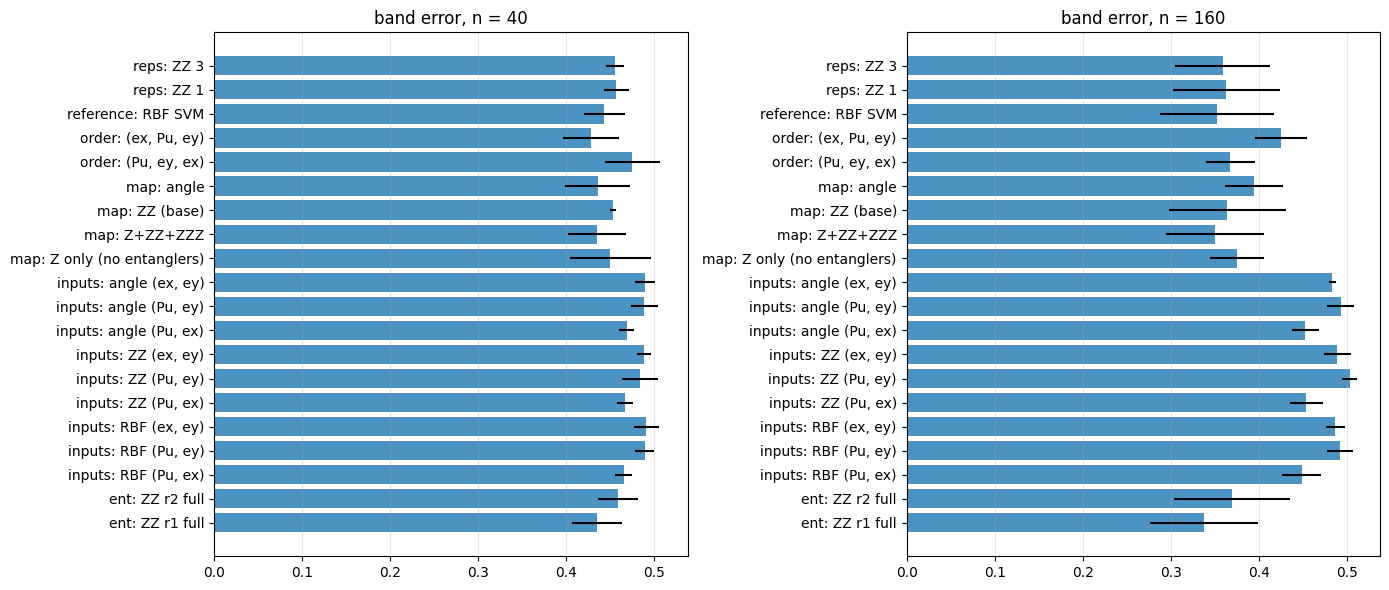

In [9]:
summary = metrics.summarise(encoding_results, "band_error", ("model", "train_size"))
figure, axes = plt.subplots(1, len(ABLATION_SIZES), figsize = (7 * len(ABLATION_SIZES), 6), sharex = True)
axes = np.atleast_1d(axes)
for axis, size in zip(axes, ABLATION_SIZES):
    part = summary[summary["train_size"] == size].sort_values("model")
    axis.barh(part["model"], part["mean"], xerr = part["ci95"], color = "tab:blue", alpha = 0.8)
    axis.set_title(f"band error, n = {size}")
    axis.grid(axis = "x", alpha = 0.3)
figure.tight_layout()
figure.savefig(config.figures_dir() / "ablation_encoding_band_error.png", dpi = 200)
plt.show()

**How to read it.** An arm that does not move the error away from the base shows that the ingredient it removed was not
contributing. The entanglement rows answer whether the ZZ terms matter. The input-feature rows show whether all three
features are needed, and the RBF rows on the same two features show whether the loss is specific to the quantum model.

Next: `04_ablations/02_training_ablations.ipynb`.